# 8.3 EDPs Elípticas 

Equações elípticas descrevem situações de **equilíbrio**: a distribuição de temperatura em uma placa depois que o regime transiente terminou, o potencial elétrico em uma região sem cargas livres ou a deflexão de uma membrana sob carga estática. Nesses problemas não há variável tempo, e o valor da solução em cada ponto depende do que é imposto em toda a fronteira do domínio. Na Seção 8.2 vimos que uma EDP linear de segunda ordem é elíptica quando $B^2-4AC<0$; o exemplo mais importante é o operador laplaciano.

Nesta seção vamos tratar a **equação de Poisson** em um retângulo $\Omega=[a,b]\times[c,d]$,

$$\frac{\partial^2 u}{\partial x^2}+\frac{\partial^2 u}{\partial y^2}=f(x,y), \qquad (x,y)\in\Omega, \tag{1}$$

com o valor de $u$ prescrito em toda a fronteira $\partial\Omega$ (condição de Dirichlet):

$$u(x,y)=g(x,y), \qquad (x,y)\in\partial\Omega. \tag{2}$$

Quando $f\equiv 0$, a Eq. (1) é a **equação de Laplace**. Na condução de calor em regime permanente, por exemplo, $u$ é a temperatura e $f=-q/k$, em que $q$ é a taxa de geração interna de calor (em W/m³) e $k$ é a condutividade térmica do material.

### A malha e o estêncil de cinco pontos

Dividimos o intervalo $[a,b]$ em $n_x$ subintervalos de comprimento $h_x=(b-a)/n_x$ e o intervalo $[c,d]$ em $n_y$ subintervalos de comprimento $h_y=(d-c)/n_y$, obtendo os nós

$$x_i=a+i\,h_x,\quad i=0,1,\ldots,n_x, \qquad\qquad y_j=c+j\,h_y,\quad j=0,1,\ldots,n_y.$$

Denotamos por $u_{i,j}$ a aproximação de $u(x_i,y_j)$ e escrevemos $f_{i,j}=f(x_i,y_j)$. Os nós com $i\in\{0,n_x\}$ ou $j\in\{0,n_y\}$ estão na fronteira, onde $u$ é conhecido pela Eq. (2). Os $(n_x-1)(n_y-1)$ nós restantes são as incógnitas do problema.

![](imagens/estencil_cinco_pontos.png)

Figura 8.3.1 - Malha retangular e estêncil de cinco pontos em torno do nó $(x_i,y_j)$.

Em cada nó interno, aproximamos as derivadas segundas por diferenças centrais. Somando as expansões de Taylor

$$u(x_i\pm h_x,y_j)=u \pm h_x\frac{\partial u}{\partial x}+\frac{h_x^2}{2}\frac{\partial^2 u}{\partial x^2}\pm\frac{h_x^3}{6}\frac{\partial^3 u}{\partial x^3}+\frac{h_x^4}{24}\frac{\partial^4 u}{\partial x^4}+\cdots,$$

em que $u$ e suas derivadas são calculadas em $(x_i,y_j)$, os termos de ordem ímpar se cancelam e obtemos

$$\frac{\partial^2 u}{\partial x^2}(x_i,y_j)=\frac{u(x_{i+1},y_j)-2u(x_i,y_j)+u(x_{i-1},y_j)}{h_x^2}-\frac{h_x^2}{12}\frac{\partial^4 u}{\partial x^4}(\xi,y_j)$$

para algum $\xi\in(x_{i-1},x_{i+1})$. O mesmo vale na direção $y$, com $h_y$ no lugar de $h_x$. Substituindo essas aproximações na Eq. (1) e desprezando os termos de erro, chegamos às equações de diferenças finitas

$$\frac{u_{i+1,j}-2u_{i,j}+u_{i-1,j}}{h_x^2}+\frac{u_{i,j+1}-2u_{i,j}+u_{i,j-1}}{h_y^2}=f_{i,j}, \qquad i=1,\ldots,n_x-1,\quad j=1,\ldots,n_y-1. \tag{3}$$

Cada equação envolve apenas o nó $(x_i,y_j)$ e seus quatro vizinhos, que formam o **estêncil de cinco pontos** da Figura 8.3.1. Como os termos desprezados são proporcionais a $h_x^2$ e $h_y^2$, esperamos que o erro da solução numérica diminua como $h^2$: ao dividir o espaçamento por 2, o erro deve cair aproximadamente por 4.

Quando $h_x=h_y=h$, a Eq. (3) assume a forma

$$u_{i+1,j}+u_{i-1,j}+u_{i,j+1}+u_{i,j-1}-4u_{i,j}=h^2 f_{i,j}.$$

Para a equação de Laplace ($f=0$), isso diz que cada $u_{i,j}$ é a média dos valores nos quatro vizinhos. É a versão discreta da propriedade do valor médio das funções harmônicas, e ajuda a entender por que a solução da equação de Laplace é sempre "suave" e não tem máximos nem mínimos no interior do domínio.

### Montagem do sistema linear

As Eqs. (3) formam um sistema linear $A\mathbf{u}=\mathbf{b}$ com uma incógnita para cada nó interno. Para escrevê-lo, numeramos os nós internos percorrendo primeiro a direção $y$: o nó $(i,j)$ recebe o índice $k=(i-1)(n_y-1)+(j-1)$. Com essa ordenação, a matriz pode ser escrita de forma compacta com o **produto de Kronecker** $\otimes$:

$$A=\frac{1}{h_x^2}\,T_{n_x-1}\otimes I_{n_y-1}+\frac{1}{h_y^2}\,I_{n_x-1}\otimes T_{n_y-1}, \tag{4}$$

em que $I_m$ é a matriz identidade de ordem $m$ e $T_m$ é a matriz tridiagonal de ordem $m$ com $-2$ na diagonal principal e $1$ nas diagonais vizinhas, que representa a segunda diferença em uma dimensão. Lembre que $P\otimes Q$ é a matriz em blocos cujo bloco $(r,s)$ é $p_{rs}\,Q$. O primeiro termo da Eq. (4) acopla cada nó a seus vizinhos na direção $x$, e o segundo, aos vizinhos na direção $y$.

O vetor $\mathbf{b}$ contém os valores $f_{i,j}$, corrigidos nos nós vizinhos à fronteira: quando um dos quatro vizinhos de $(x_i,y_j)$ está na fronteira, seu valor é conhecido e passa para o lado direito da equação. Por exemplo, para $i=1$, o termo $u_{0,j}/h_x^2$ é subtraído de $f_{1,j}$.

A matriz $A$ tem ordem $(n_x-1)(n_y-1)$, mas no máximo cinco elementos não nulos por linha. Em uma malha com $n_x=n_y=100$, são cerca de $10^4$ incógnitas e $5\times 10^4$ elementos não nulos, em uma matriz com quase $10^8$ posições. Por isso, armazenamos $A$ no formato **esparso** do módulo `scipy.sparse`, que guarda apenas os elementos não nulos, e resolvemos o sistema com `scipy.sparse.linalg.spsolve`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla

Para visualizar a estrutura da matriz, vamos montá-la para uma malha pequena, com $n_x=5$, $n_y=6$ e $h_x=h_y=1$, e marcar os elementos não nulos com a função `plt.spy`.

ordem da matriz: 20, elementos não nulos: 82


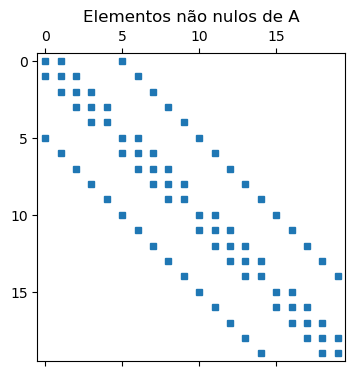

In [2]:
def segunda_diferenca(n):
    """Matriz tridiagonal de ordem n com (1, -2, 1) nas diagonais."""
    return sp.diags([1, -2, 1], [-1, 0, 1], shape=(n, n))

nx, ny = 5, 6
A = (sp.kron(segunda_diferenca(nx - 1), sp.identity(ny - 1))
     + sp.kron(sp.identity(nx - 1), segunda_diferenca(ny - 1)))

print(f"ordem da matriz: {A.shape[0]}, elementos não nulos: {A.nnz}")

fig, ax = plt.subplots(figsize=(4, 4))
ax.spy(A, markersize=5)
ax.set_title('Elementos não nulos de A')
plt.show()

A matriz é **tridiagonal por blocos**: os blocos da diagonal, de ordem $n_y-1=5$, são tridiagonais e ligam cada nó aos vizinhos na direção $y$; os blocos imediatamente acima e abaixo são múltiplos da identidade e ligam os vizinhos na direção $x$. Além disso, $A$ é simétrica e $-A$ é definida positiva, o que garante que o sistema tem solução única.

A rotina a seguir reúne todos esses passos. As funções `f` e `g` devem aceitar arrays do NumPy, e `g` é avaliada apenas nos nós da fronteira. A solução é devolvida em uma matriz `U` em que `U[i, j]` aproxima $u(x_i,y_j)$.

In [3]:
def poisson_dirichlet(f, g, a, b, c, d, nx, ny):
    """
    Resolve u_xx + u_yy = f(x, y) no retângulo [a, b] x [c, d], com
    u = g(x, y) na fronteira, pelo método de diferenças finitas com o
    estêncil de cinco pontos.

    Retorna os vetores x e y dos nós e a matriz U, com U[i, j] ~ u(x[i], y[j]).
    """
    x = np.linspace(a, b, nx + 1)
    y = np.linspace(c, d, ny + 1)
    X, Y = np.meshgrid(x, y, indexing='ij')
    hx2 = (x[1] - x[0])**2
    hy2 = (y[1] - y[0])**2

    # valores prescritos na fronteira
    U = np.zeros((nx + 1, ny + 1))
    U[0, :] = g(x[0], y)
    U[-1, :] = g(x[-1], y)
    U[:, 0] = g(x, y[0])
    U[:, -1] = g(x, y[-1])

    # matriz do sistema, Eq. (4)
    A = (sp.kron(segunda_diferenca(nx - 1), sp.identity(ny - 1)) / hx2
         + sp.kron(sp.identity(nx - 1), segunda_diferenca(ny - 1)) / hy2)

    # lado direito: f nos nós internos menos a contribuição da fronteira
    B = f(X[1:-1, 1:-1], Y[1:-1, 1:-1]) * np.ones((nx - 1, ny - 1))
    B[0, :] -= U[0, 1:-1] / hx2
    B[-1, :] -= U[-1, 1:-1] / hx2
    B[:, 0] -= U[1:-1, 0] / hy2
    B[:, -1] -= U[1:-1, -1] / hy2

    # resolve e devolve os valores aos nós internos
    U[1:-1, 1:-1] = spla.spsolve(A.tocsr(), B.ravel()).reshape(nx - 1, ny - 1)
    return x, y, U

**Exemplo 8.3.1:** Verificação com uma solução conhecida

Uma boa maneira de testar um programa como esse é escolher uma função $u$, calcular o lado direito $f=\nabla^2 u$ correspondente e verificar se a solução numérica reproduz a função escolhida. Tomemos

$$u(x,y)=\sin(\pi x)\sin(\pi y)+xy, \qquad 0\leq x\leq 1,\quad 0\leq y\leq 1.$$

Como $\nabla^2(xy)=0$, temos $f(x,y)=-2\pi^2\sin(\pi x)\sin(\pi y)$. Os valores na fronteira são os da própria $u$: $u=0$ nas bordas $x=0$ e $y=0$, $u=y$ na borda $x=1$ e $u=x$ na borda $y=1$. Vamos resolver o problema em malhas cada vez mais finas e medir o erro máximo nos nós.

In [4]:
u_exata = lambda x, y: np.sin(np.pi*x)*np.sin(np.pi*y) + x*y
f = lambda x, y: -2*np.pi**2*np.sin(np.pi*x)*np.sin(np.pi*y)

malhas = [10, 20, 40, 80]
erros = []
print(f"{'n':>4} {'h':>8} {'erro máximo':>13} {'razão':>7}")
for n in malhas:
    x, y, U = poisson_dirichlet(f, u_exata, 0, 1, 0, 1, n, n)
    X, Y = np.meshgrid(x, y, indexing='ij')
    erros.append(np.max(np.abs(U - u_exata(X, Y))))
    razao = f"{erros[-2]/erros[-1]:7.2f}" if len(erros) > 1 else ""
    print(f"{n:4d} {1/n:8.4f} {erros[-1]:13.3e} {razao}")

   n        h   erro máximo   razão
  10   0.1000     8.265e-03 
  20   0.0500     2.059e-03    4.01
  40   0.0250     5.142e-04    4.00
  80   0.0125     1.285e-04    4.00


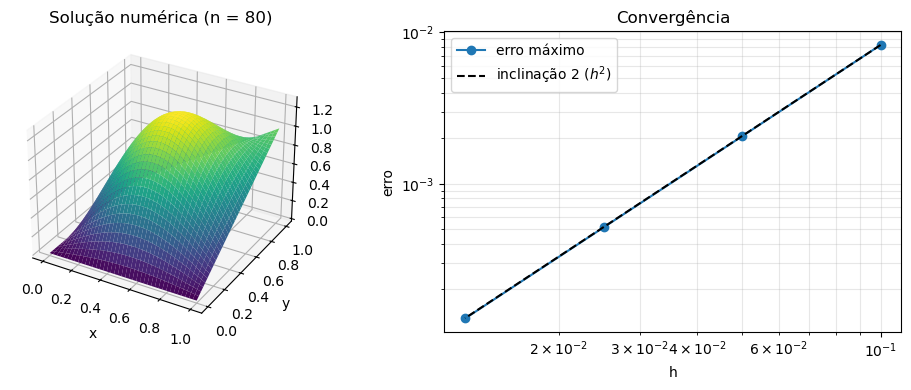

In [5]:
h = 1 / np.array(malhas)

fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(X, Y, U, cmap='viridis')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title(f'Solução numérica (n = {malhas[-1]})')

ax2 = fig.add_subplot(1, 2, 2)
ax2.loglog(h, erros, 'o-', label='erro máximo')
ax2.loglog(h, erros[0]*(h/h[0])**2, 'k--', label='inclinação 2 ($h^2$)')
ax2.set_xlabel('h')
ax2.set_ylabel('erro')
ax2.set_title('Convergência')
ax2.legend()
ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

Cada vez que $h$ é dividido por 2, o erro é dividido por 4, e no gráfico em escala logarítmica os pontos ficam sobre uma reta de inclinação 2. Isso confirma que o método tem **ordem 2**, como previsto pela análise do erro de truncamento.

**Exemplo 8.3.2:** Placa com geração interna de calor

Uma placa de aço inoxidável de $20\,\text{cm}\times 10\,\text{cm}$, com condutividade térmica $k=15\,\text{W/(m·K)}$, tem uma resistência elétrica embutida que gera calor de modo uniforme, à taxa $q=5\times 10^5\,\text{W/m}^3$. A borda inferior está em contato com uma superfície a $60\,°C$, e as outras três bordas são mantidas a $20\,°C$. Supondo que as faces da placa estejam isoladas, de modo que o calor flua apenas no plano da placa, a temperatura em regime permanente satisfaz

$$\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}=-\frac{q}{k}, \qquad 0\leq x\leq 0{,}2,\quad 0\leq y\leq 0{,}1,$$

com $x$ e $y$ em metros. Qual é a temperatura máxima na placa e onde ela ocorre?

Temperatura máxima: 78.6 graus C
Posição: x = 0.100 m, y = 0.035 m


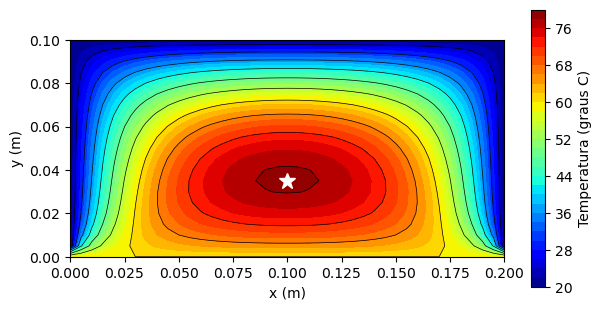

In [6]:
k = 15.0      # condutividade térmica, W/(m.K)
q = 5e5       # geração de calor, W/m^3

def T_contorno(x, y):
    # 60 graus C na borda inferior (y = 0) e 20 graus C nas demais
    return np.where(y == 0, 60.0, 20.0) * np.ones_like(x + y)

x, y, T = poisson_dirichlet(lambda x, y: -q/k, T_contorno, 0, 0.2, 0, 0.1, 40, 20)

i, j = np.unravel_index(np.argmax(T), T.shape)
print(f"Temperatura máxima: {T[i, j]:.1f} graus C")
print(f"Posição: x = {x[i]:.3f} m, y = {y[j]:.3f} m")

X, Y = np.meshgrid(x, y, indexing='ij')
fig, ax = plt.subplots(figsize=(7, 3.6))
cf = ax.contourf(X, Y, T, levels=30, cmap='jet')
ax.contour(X, Y, T, levels=10, colors='k', linewidths=0.5)
ax.plot(x[i], y[j], 'w*', markersize=12)
ax.set_aspect('equal')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
plt.colorbar(cf, ax=ax, label='Temperatura (graus C)')
plt.show()

A temperatura máxima, de cerca de $78{,}6\,°C$, ocorre no eixo de simetria vertical da placa ($x=0{,}1$ m), mas abaixo do centro geométrico, deslocada na direção da borda inferior, que é a mais quente. Sem a fonte de calor ($q=0$), a temperatura ficaria entre $20\,°C$ e $60\,°C$ em toda a placa: uma solução da equação de Laplace atinge seus valores máximo e mínimo na fronteira do domínio (**princípio do máximo**), o que está de acordo com a propriedade do valor médio vista acima.

### Método iterativo de Gauss-Seidel

A rotina `poisson_dirichlet()` resolve o sistema (3) por um método direto. Como o número de incógnitas cresce com o quadrado do número de subdivisões, em malhas muito finas, e sobretudo em problemas tridimensionais, a eliminação torna-se cara em tempo e memória, mesmo aproveitando a esparsidade. Além disso, nem sempre é conveniente montar a matriz explicitamente.

Uma alternativa eficiente é o **método iterativo de Gauss-Seidel** (também chamado de método de Liebmann no contexto de EDPs). Para a equação de Laplace, a equação de diferenças finitas

$$T_{i-1,j} + T_{i+1,j} + T_{i,j-1} + T_{i,j+1} - 4T_{i,j} = 0$$

pode ser reescrita na forma de atualização

$$T_{i,j} = \frac{T_{i-1,j} + T_{i+1,j} + T_{i,j-1} + T_{i,j+1}}{4}$$

O algoritmo inicializa o campo com um valor estimado (por exemplo, a média das temperaturas de contorno), aplica essa fórmula repetidamente para cada nó interno — usando sempre os valores mais recentes disponíveis — e itera até que o erro relativo entre iterações consecutivas seja menor que uma tolerância $\varepsilon$:

$$\text{err} = \frac{\|\,T^{(k+1)} - T^{(k)}\,\|}{\|\,T^{(k+1)}\,\|} < \varepsilon$$

**Exemplo 8.3.3:** Placa aquecida — método de Gauss-Seidel

Considere uma placa quadrada (Chapra, 2016) com temperaturas constantes nas bordas:

| Borda | Temperatura |
|---|---|
| Inferior | 75 °C |
| Superior | 50 °C |
| Esquerda | 0 °C |
| Direita | 100 °C |

Resolver por Gauss-Seidel com tolerância $\varepsilon = 10^{-4}$ e malha $20 \times 20$.

Convergência em 194 iterações


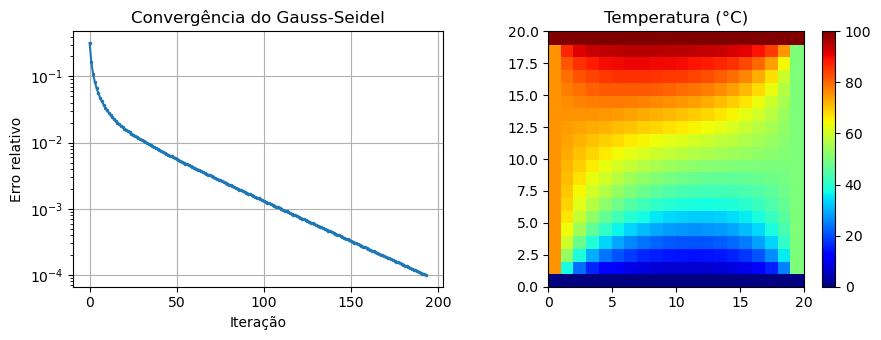

In [7]:
import numpy as np
import matplotlib.pyplot as plt

ni, nj = 20, 20

T = np.zeros((ni, nj))
T[0,  :] = 75    # borda inferior
T[-1, :] = 50    # borda superior
T[:,  0] = 0     # borda esquerda
T[:, -1] = 100   # borda direita

T_ant = T.copy()
err_hist = []
err = 1.0

while err > 1e-4:
    for i in range(1, ni - 1):
        for j in range(1, nj - 1):
            T[i, j] = (T[i-1, j] + T[i+1, j] + T[i, j-1] + T[i, j+1]) / 4
    err = np.linalg.norm(T - T_ant) / np.linalg.norm(T)
    err_hist.append(err)
    T_ant = T.copy()

print(f"Convergência em {len(err_hist)} iterações")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

axes[0].plot(err_hist, '.-', markersize=3)
axes[0].set_yscale('log')
axes[0].set_xlabel('Iteração')
axes[0].set_ylabel('Erro relativo')
axes[0].set_title('Convergência do Gauss-Seidel')
axes[0].grid(True)

im = axes[1].pcolor(T.T, cmap='jet')
axes[1].set_aspect('equal')
axes[1].set_title('Temperatura (°C)')
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

### Sobrerelaxação (SOR)

O método de **sobrerelaxação sucessiva** (SOR, do inglês *Successive Over-Relaxation*) acelera a convergência do Gauss-Seidel aplicando um fator de peso $\omega \in (1, 2)$ após cada atualização:

$$T_{i,j}^{\text{novo}} = \omega\,\tilde{T}_{i,j} + (1-\omega)\,T_{i,j}^{\text{ant}}$$

onde $\tilde{T}_{i,j}$ é o valor calculado pela fórmula de Gauss-Seidel. Para $\omega = 1$ recupera-se o método original; valores $\omega > 1$ induzem uma extrapolação na direção da atualização, acelerando a convergência. O valor ótimo de $\omega$ depende do problema, mas valores entre $1{,}2$ e $1{,}9$ são tipicamente eficazes.

Gauss-Seidel  : 194 iterações
SOR (omega=1.5): 78 iterações


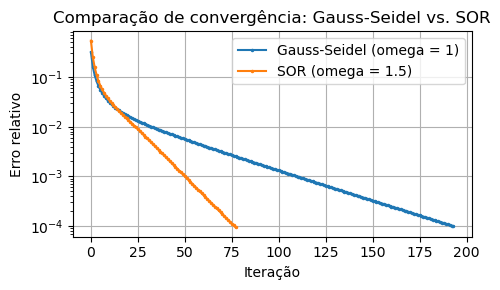

In [8]:
T_sor = np.zeros((ni, nj))
T_sor[0,  :] = 75
T_sor[-1, :] = 50
T_sor[:,  0] = 0
T_sor[:, -1] = 100

omega = 1.5
T_ant = T_sor.copy()
err_sor = []
err = 1.0

while err > 1e-4:
    for i in range(1, ni - 1):
        for j in range(1, nj - 1):
            T_gs = (T_sor[i-1, j] + T_sor[i+1, j] + T_sor[i, j-1] + T_sor[i, j+1]) / 4
            T_sor[i, j] = omega * T_gs + (1 - omega) * T_sor[i, j]
    err = np.linalg.norm(T_sor - T_ant) / np.linalg.norm(T_sor)
    err_sor.append(err)
    T_ant = T_sor.copy()

print(f"Gauss-Seidel  : {len(err_hist)} iterações")
print(f"SOR (omega={omega}): {len(err_sor)} iterações")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(err_hist, '.-', markersize=3, label='Gauss-Seidel (omega = 1)')
ax.plot(err_sor,  '.-', markersize=3, label=f'SOR (omega = {omega})')
ax.set_yscale('log')
ax.set_xlabel('Iteração')
ax.set_ylabel('Erro relativo')
ax.set_title('Comparação de convergência: Gauss-Seidel vs. SOR')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

### Gradiente e fluxo de calor

A distribuição de temperatura $T(x,y)$ determina o **vetor fluxo de calor** em cada ponto da placa. Pela lei de Fourier, o fluxo aponta na direção do gradiente negativo de temperatura:

$$\mathbf{q} = -k'\,\nabla T$$

A função `np.gradient` calcula numericamente as componentes $\partial T/\partial x$ e $\partial T/\partial y$ a partir da solução discreta, e `plt.quiver` exibe o campo vetorial sobreposto à distribuição de temperatura.

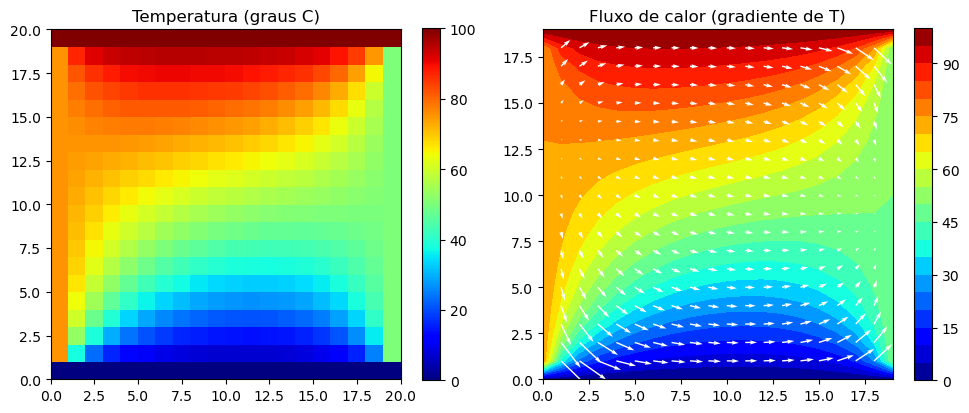

In [9]:
dTdy, dTdx = np.gradient(T[1:-1, 1:-1])
ii, jj = np.meshgrid(np.arange(1, nj - 1), np.arange(1, ni - 1))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im = axes[0].pcolor(T.T, cmap='jet')
axes[0].set_aspect('equal')
axes[0].set_title('Temperatura (graus C)')
plt.colorbar(im, ax=axes[0])

cf = axes[1].contourf(T.T, levels=20, cmap='jet')
axes[1].quiver(jj, ii, dTdx, dTdy, color='white', scale=200, width=0.004)
axes[1].set_aspect('equal')
axes[1].set_title('Fluxo de calor (gradiente de T)')
plt.colorbar(cf, ax=axes[1])

plt.tight_layout()
plt.show()

### Condição de contorno de Neumann

Nos exemplos anteriores, as bordas tinham temperatura prescrita — denominadas **condições de Dirichlet**. Em muitas situações práticas, porém, o que é dado é o **fluxo de calor** na borda, isto é, a derivada normal à superfície. Essas são chamadas **condições de Neumann**.

O caso mais frequente em engenharia é a **borda isolada**, na qual o fluxo é nulo:

$$\left.\frac{\partial T}{\partial n}\right|_{\text{borda}} = 0$$

**Estratégia do ponto fictício.** Para incorporar essa condição no esquema de diferenças finitas, introduz-se um **nó fictício** externo à malha, cujo valor é eliminado algebricamente usando a aproximação por diferenças centrais da derivada.

Para a borda inferior ($j = 0$), a condição de isolamento resulta em:

$$\frac{T_{i,1} - T_{i,-1}}{2\,\Delta y} = 0 \implies T_{i,-1} = T_{i,1}$$

Substituindo na equação do nó $(i, 0)$:

$$T_{i-1,\,0} + T_{i+1,\,0} + 2\,T_{i,\,1} - 4\,T_{i,\,0} = 0$$

O coeficiente **2** no vizinho superior (em vez de 1) é a única modificação em relação à equação interior padrão, refletindo a simetria imposta pelo isolamento.

**Fluxo de calor nas bordas**

A partir da solução numérica, o vetor fluxo de calor pode ser estimado por diferenças finitas centrais e pela lei de Fourier (Chapra e Canale, 2016):

$$q_x = -k'\frac{T_{i+1,j} - T_{i-1,j}}{2\,\Delta x}, \qquad q_y = -k'\frac{T_{i,j+1} - T_{i,j-1}}{2\,\Delta y}$$

O módulo do fluxo resultante é $q_n = \sqrt{q_x^2 + q_y^2}$ e sua direção é $\theta = \arctan(q_y / q_x)$.

**Exemplo 8.3.4:** Placa aquecida com borda inferior isolada

(Fonte: Chapra e Canale, 2016) Placa de $4\,\text{cm} \times 4\,\text{cm}$ com as seguintes condições de contorno:

| Borda | Condição |
|---|---|
| Esquerda ($x = 0$) | $T = 75\,°C$ (Dirichlet) |
| Direita ($x = 4\,\text{cm}$) | $T = 50\,°C$ (Dirichlet) |
| Superior ($y = 4\,\text{cm}$) | $T = 100\,°C$ (Dirichlet) |
| Inferior ($y = 0$) | $\partial T/\partial y = 0$ (Neumann — isolada) |

Com $\Delta x = \Delta y = 1\,\text{cm}$, a borda inferior passa a ser uma linha de nós ativos (em vez de nós com valor prescrito). O sistema tem $3 \times 4 = 12$ incógnitas.

![](imagens/edp_eliptica_neumann.png)

In [10]:
# Sistema 12x12 — nós da borda inferior incluídos (Neumann)
# Linhas: j = 0 (inferior, isolada) até j = 3 (interior)
# Colunas: i = 1, 2, 3 (interior em x)
A_neu = np.array([
    [ 4,-1, 0,-2, 0, 0, 0, 0, 0, 0, 0, 0],
    [-1, 4,-1, 0,-2, 0, 0, 0, 0, 0, 0, 0],
    [ 0,-1, 4, 0, 0,-2, 0, 0, 0, 0, 0, 0],
    [-1, 0, 0, 4,-1, 0,-1, 0, 0, 0, 0, 0],
    [ 0,-1, 0,-1, 4,-1, 0,-1, 0, 0, 0, 0],
    [ 0, 0,-1, 0,-1, 4, 0, 0,-1, 0, 0, 0],
    [ 0, 0, 0,-1, 0, 0, 4,-1, 0,-1, 0, 0],
    [ 0, 0, 0, 0,-1, 0,-1, 4,-1, 0,-1, 0],
    [ 0, 0, 0, 0, 0,-1, 0,-1, 4, 0, 0,-1],
    [ 0, 0, 0, 0, 0, 0,-1, 0, 0, 4,-1, 0],
    [ 0, 0, 0, 0, 0, 0, 0,-1, 0,-1, 4,-1],
    [ 0, 0, 0, 0, 0, 0, 0, 0,-1, 0,-1, 4]
], dtype=float)

b_neu = np.array([75, 0, 50, 75, 0, 50, 75, 0, 50, 175, 100, 150], dtype=float)

T_int = np.linalg.solve(A_neu, b_neu).reshape(4, 3)
print("Temperaturas nos nos internos e na borda inferior (linhas=y crescente, colunas=x):")
print(np.flipud(np.round(T_int, 2)))

Temperaturas nos nos internos e na borda inferior (linhas=y crescente, colunas=x):
[[83.41 82.63 74.26]
 [76.02 72.84 64.42]
 [72.81 68.31 60.57]
 [71.91 67.01 59.54]]


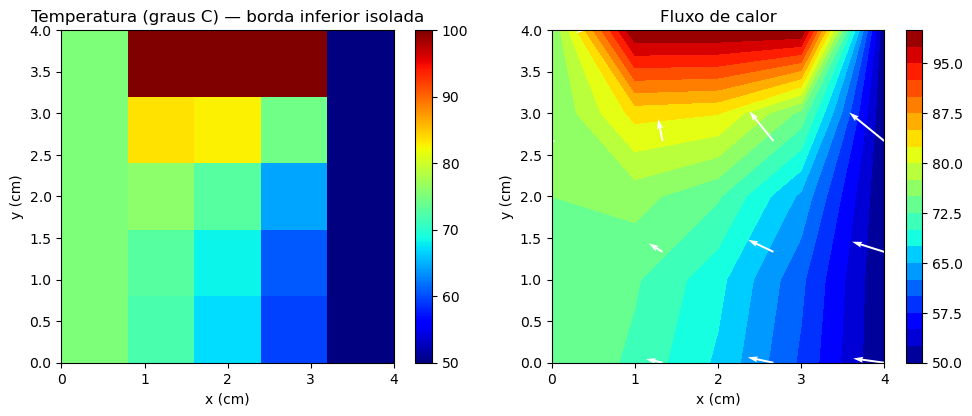

In [11]:
x_mesh, y_mesh = np.meshgrid(np.linspace(0, 4, 6), np.linspace(0, 4, 6))

T_neu = np.zeros((5, 5))
T_neu[-1, :] = 100   # borda superior
T_neu[:,  0] = 75    # borda esquerda
T_neu[:, -1] = 50    # borda direita
T_neu[0:-1, 1:-1] = T_int   # nos internos + borda inferior

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im = axes[0].pcolormesh(x_mesh, y_mesh, T_neu, cmap='jet', shading='flat')
axes[0].set_aspect('equal')
axes[0].set_xlabel('x (cm)')
axes[0].set_ylabel('y (cm)')
axes[0].set_title('Temperatura (graus C) — borda inferior isolada')
plt.colorbar(im, ax=axes[0])

dTdy_n, dTdx_n = np.gradient(T_neu[:-1, :-1])
ii_n, jj_n = np.meshgrid(np.linspace(0, 4, 4), np.linspace(0, 4, 4))
xn, yn = np.meshgrid(np.linspace(0,4,5),
                     np.linspace(0,4,5))

cf = axes[1].contourf(xn, yn, T_neu, levels=20, cmap='jet')
axes[1].quiver(ii_n, jj_n, dTdx_n, dTdy_n, color='white', scale=80, width=0.006)
axes[1].set_aspect('equal')
axes[1].set_xlabel('x (cm)')
axes[1].set_ylabel('y (cm)')
axes[1].set_title('Fluxo de calor')
plt.colorbar(cf, ax=axes[1])

plt.tight_layout()
plt.show()

### Exercícios

> **1.** Use a rotina `poisson_dirichlet()` nos problemas a seguir.
>
> (a) Resolva $\nabla^2 u=6(x+y)$ em $[0,1]\times[0,1]$, com $u=x^3+y^3$ na fronteira, para $n_x=n_y=4$, $8$ e $16$, e calcule o erro máximo em relação à solução exata $u(x,y)=x^3+y^3$. Por que o erro fica no nível do erro de arredondamento, mesmo em uma malha tão grosseira? (Sugestão: observe o termo de erro da aproximação das derivadas segundas.)
>
> (b) Resolva a equação de Laplace em $[0,2]\times[0,1]$, com $u=0$ nas bordas $x=0$, $y=0$ e $y=1$, e $u(2,y)=\sin(\pi y)$. A solução exata é
>
> $$u(x,y)=\frac{\sinh(\pi x)\sin(\pi y)}{\sinh(2\pi)}.$$
>
> Use $n_x=2n_y$ com $n_y=10$, $20$ e $40$, e verifique numericamente a ordem de convergência do método.
>
> (c) A deflexão de uma membrana quadrada de lado 1, presa nas bordas e submetida a uma pressão uniforme, é proporcional à solução de $\nabla^2 u=-1$ com $u=0$ na fronteira. Calcule $u(0{,}5;\,0{,}5)$ com $n_x=n_y=20$, $40$ e $80$ e compare com o valor de referência $0{,}073671$. Faça um gráfico de superfície da solução.

---

> **2.** Retome a placa aquecida do **Exemplo 8.3.3** (bordas a $75\,°C$, $50\,°C$, $0\,°C$ e $100\,°C$, malha $20\times 20$).
>
> (a) Resolva o problema com o método de SOR para $\omega = 1{,}0$; $1{,}2$; $1{,}5$; $1{,}7$ e $1{,}9$, contando o número de iterações até a convergência ($\varepsilon = 10^{-4}$) em cada caso.
>
> (b) Plote o número de iterações em função de $\omega$.
>
> (c) Com base no gráfico, estime o valor de $\omega$ que minimiza o número de iterações para esse problema.

---

> **3.** Considere a mesma placa de $4\,\text{cm}\times 4\,\text{cm}$ do **Exemplo 8.3.4**, com $\Delta x=\Delta y=1\,\text{cm}$, mas agora com a borda **direita** isolada (condição de Neumann, fluxo nulo) em vez da borda inferior. As demais bordas permanecem com condição de Dirichlet: esquerda $=75\,°C$, superior $=100\,°C$, inferior $=50\,°C$.
>
> (a) Adapte a estratégia do ponto fictício (apresentada para a borda inferior) para eliminar o nó fictício na borda direita, obtendo a equação modificada para os nós dessa borda.
>
> (b) Monte o sistema linear $12\times 12$ correspondente e resolva com `np.linalg.solve`.
>
> (c) Plote a distribuição de temperatura resultante.

---

> **4.** Utilize a solução obtida no **Exemplo 8.3.2** (placa com geração interna de calor).
>
> (a) Calcule o fluxo de calor $\mathbf{q}=-k\nabla T$ a partir da solução discreta, usando `np.gradient` com os espaçamentos da malha.
>
> (b) Plote a distribuição de temperatura e sobreponha o campo vetorial de $\mathbf{q}$ com `plt.quiver`, como foi feito no Exemplo 8.3.3.
>
> (c) Por qual das bordas sai mais calor? Justifique com base no gráfico.

---

> **5.** Compare o método direto com o método de Gauss-Seidel na placa do **Exemplo 8.3.3** (bordas a $75\,°C$, $50\,°C$, $0\,°C$ e $100\,°C$).
>
> (a) Escreva uma função `fronteira(x, y)` que reproduza essas condições de contorno e resolva o problema com `poisson_dirichlet()` para $n_x=n_y=10$, $20$, $40$ e $80$.
>
> (b) Resolva os mesmos problemas com o método de Gauss-Seidel do Exemplo 8.3.3 e meça o tempo gasto por cada método com `time.perf_counter()`.
>
> (c) Como cresce o número de iterações do Gauss-Seidel com o número de subdivisões? Qual dos métodos é mais vantajoso nas malhas finas?